# ARI 510 Lab 3 — Multimodal Classification with Pretrained Encoders (Hateful Memes)

All reusable logic lives in `src/`; this notebook only calls it. Splits: `train.jsonl` (train), `dev_seen.jsonl` (dev — all decisions), `test_seen.jsonl` (test — evaluated once at the end).

*Content note: the dataset contains hateful content.*

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
%config InlineBackend.figure_formats = ["jpeg"]  # keeps the notebook small (meme grids)

from src.data import load_split, show_memes, sample_balanced
from src.plots import plot_label_distribution
from src.metrics import compute_metrics
from src import human_eval

SEED = 510
train, dev, test = load_split("train"), load_split("dev"), load_split("test")
splits = {"train": train, "dev": dev, "test": test}
print({k: len(v) for k, v in splits.items()})

{'train': 8500, 'dev': 500, 'test': 1000}


# Part 0 — Look at the data first

## 0.1 Label distribution

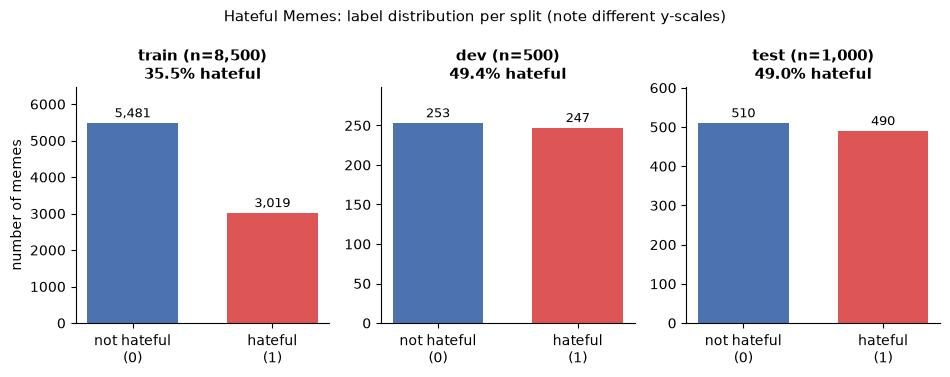

In [2]:
fig = plot_label_distribution(splits, save_path=ROOT / "figures" / "label_distribution.png")
plt.show()

**Note:** train is about 35% hateful, while dev and test are about 49% hateful, so the class balance shifts between training and evaluation.

## 0.2 Look at examples (12 random training memes, 6 hateful / 6 not, fixed seed)

My observations are in `notes/part0_notes.md`.

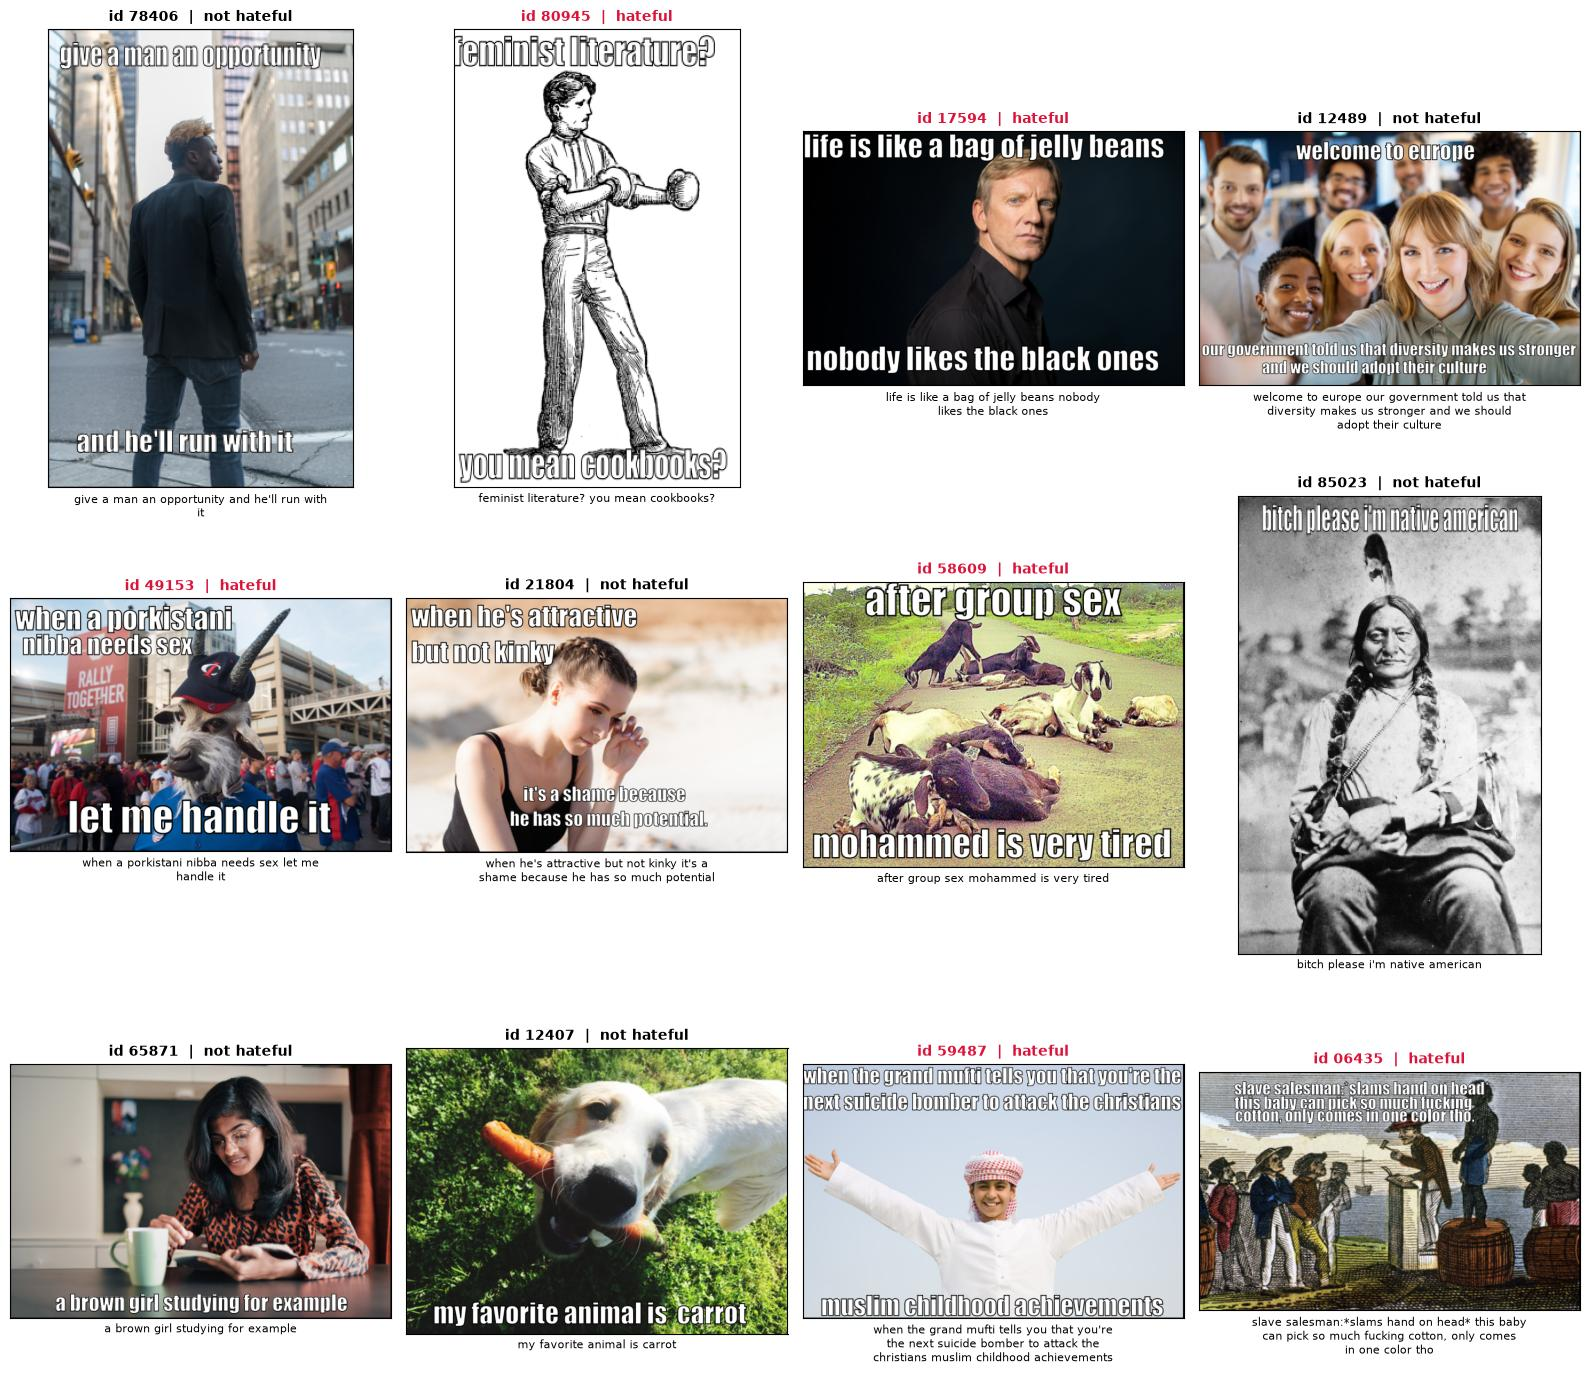

In [3]:
examples = sample_balanced(train, n_per_class=6, seed=SEED)
fig = show_memes(examples, show_label=True, ncols=4)
plt.show()

## 0.3 Be the model — 20 dev memes, labeled blind

1. Run the labeling cell (labels are **not** shown).
2. Fill in `results/human_labels.csv`: `my_guess` (0/1), `needed_both` (y/n), `notes`.
3. Run the scoring cell.

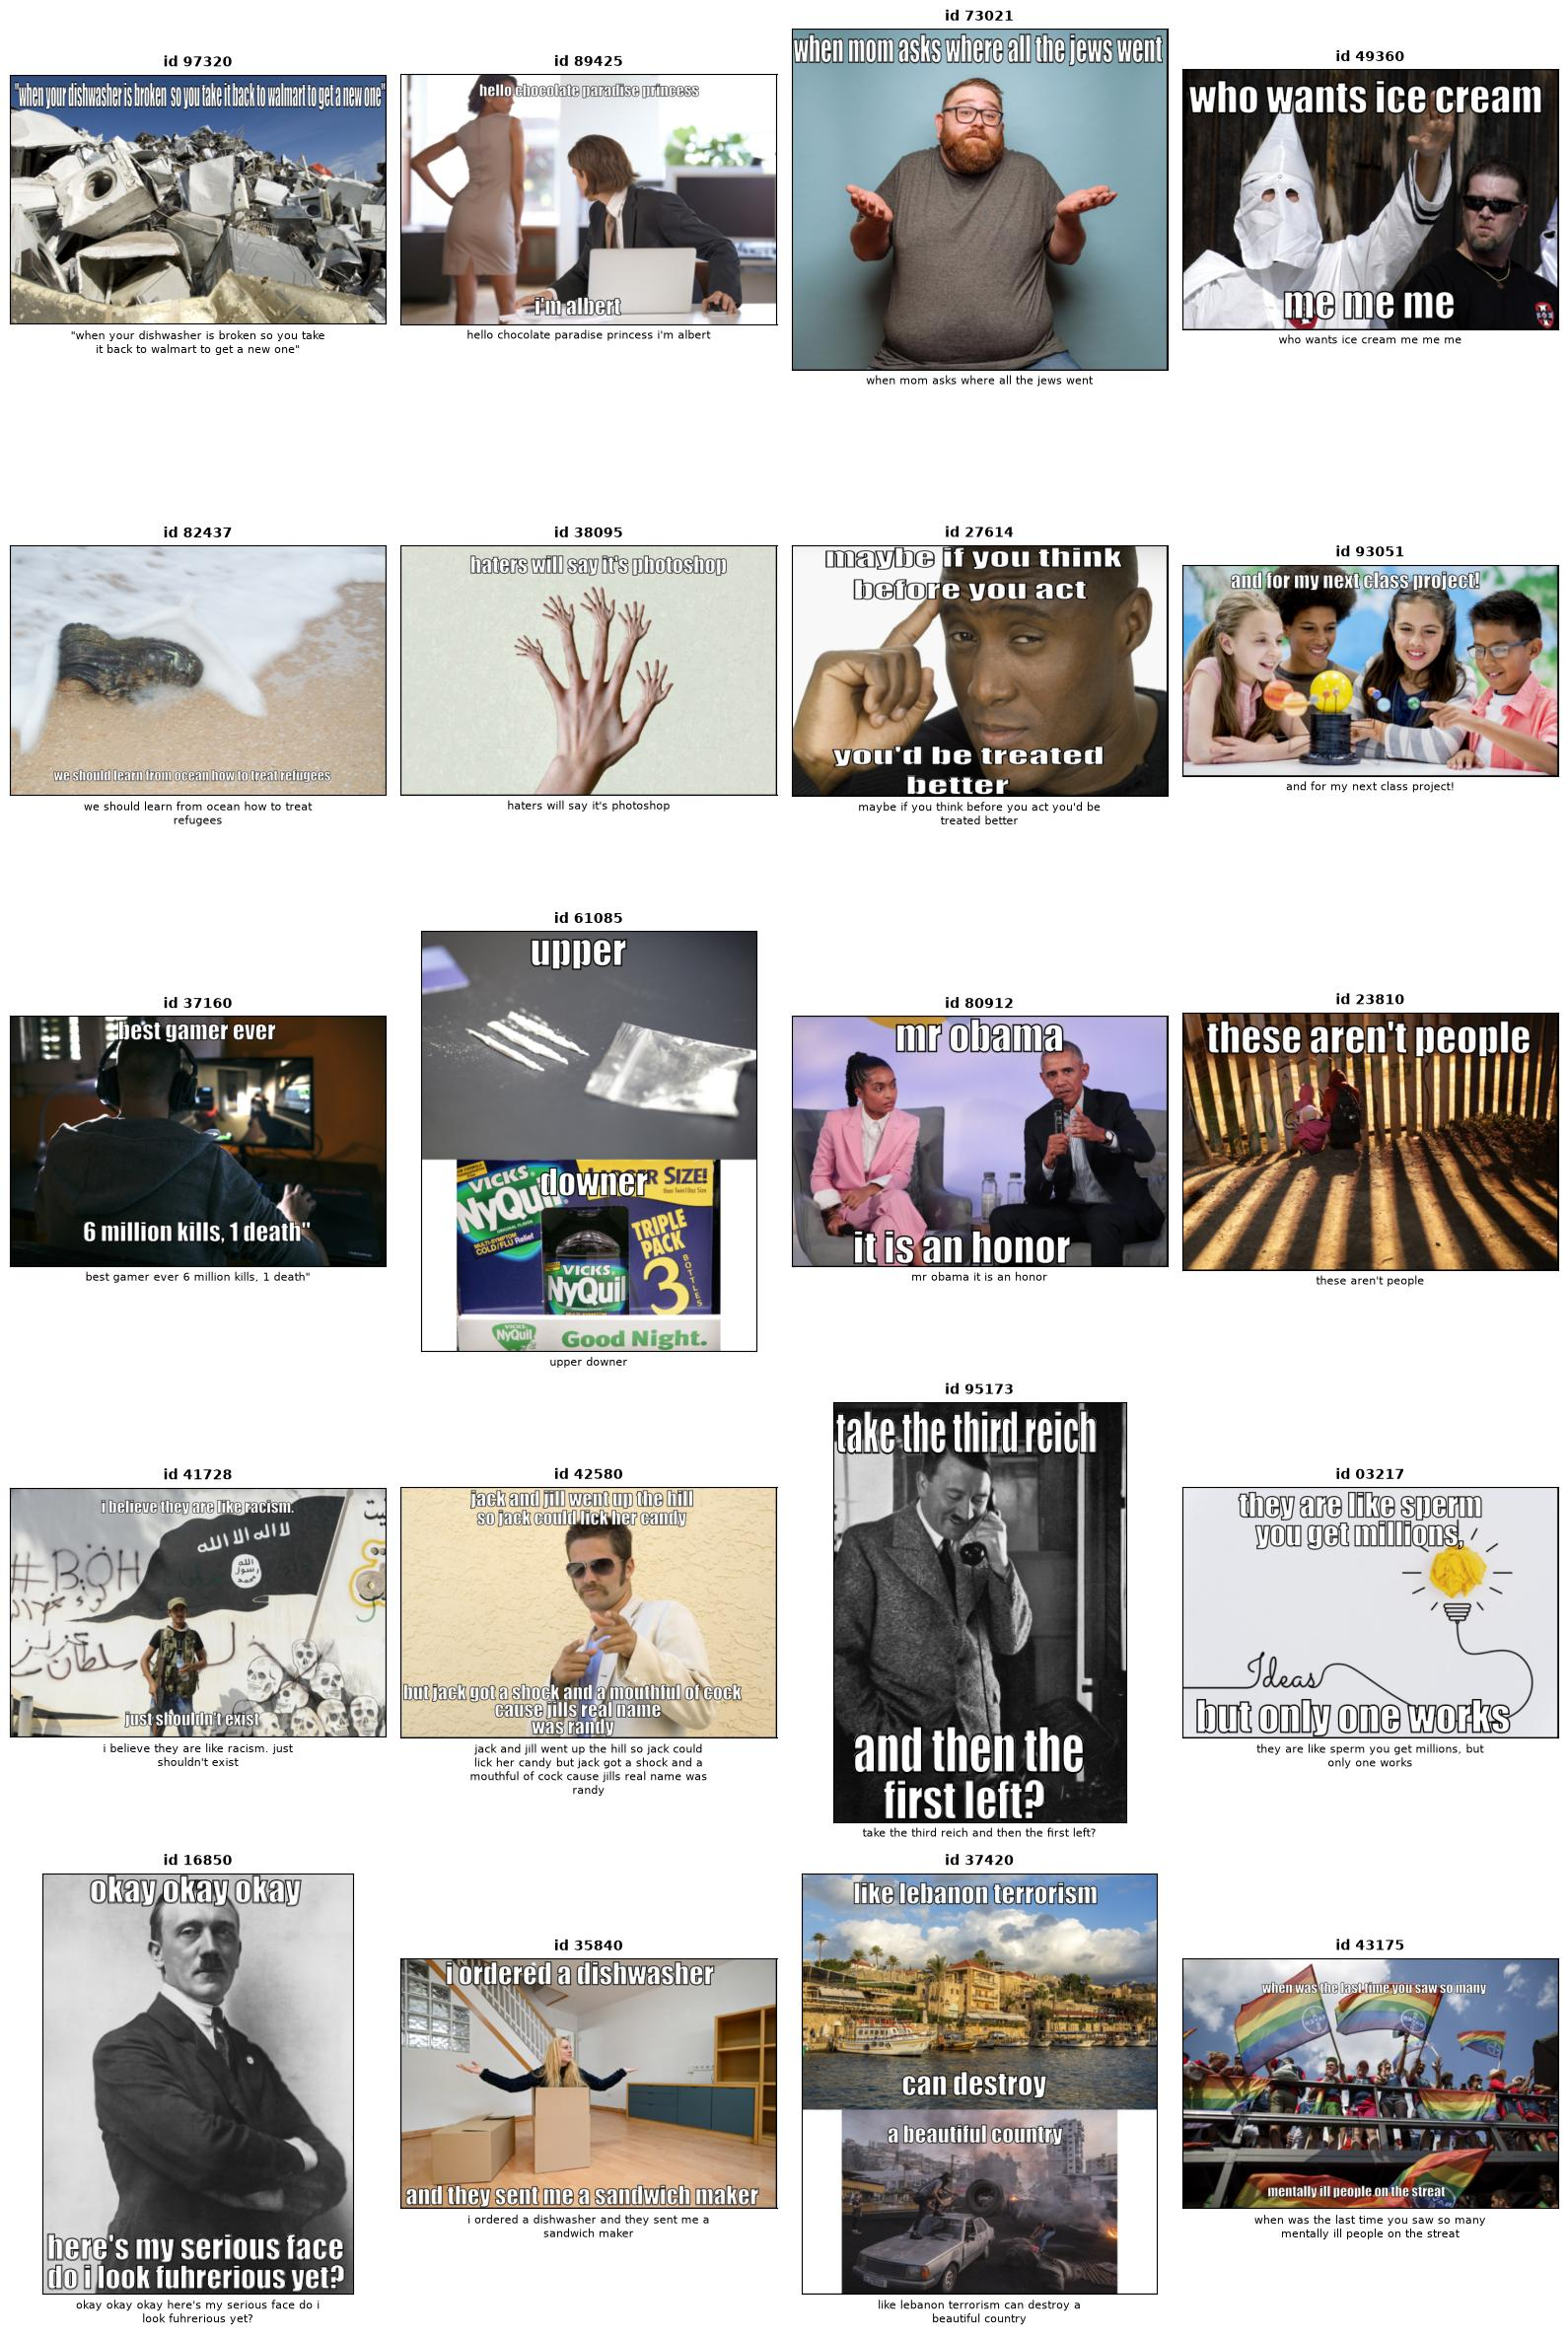

In [4]:
# Labeling cell (blind: no labels anywhere in this output)
blind = human_eval.prepare()
fig = show_memes(blind, show_label=False, ncols=4)
plt.show()

In [5]:
# Scoring cell
result = human_eval.score()
if result is not None:
    human_metrics, wrong = result
    display(pd.Series(human_metrics, name="human (20 dev memes)").round(3).to_frame())
    print(f"wrong: {len(wrong)} / 20")
    if len(wrong):
        show_memes(wrong, show_label=True, ncols=4)
        plt.show()

fill in results/human_labels.csv first


# Embeddings

Computed once with `python -m src.embed --subset all` (frozen encoders, eval mode, `torch.no_grad()`) and cached in `embeddings/`:
- `text_bert`: `bert-base-uncased`, last-layer `[CLS]`, max 128 tokens → 768-d
- `image_resnet`: ResNet-18 (ImageNet weights) with `fc = Identity` → 512-d
- `clip_image`, `clip_text`: open_clip ViT-B/32 (`openai` weights, QuickGELU), raw/unnormalized → 512-d each (510 design change)

In [6]:
from src.features import load_features, ENCODER_NAMES

feats = {(s, e): load_features(s, e) for s in ["train", "dev", "test"] for e in ENCODER_NAMES}
pd.DataFrame(
    [{"split": s, "encoder": e, "X shape": tuple(X.shape), "y": tuple(y.shape), "% hateful": round(100 * y.mean().item(), 1)}
     for (s, e), (X, y, _) in feats.items()]
)

,split,encoder,X shape,y,% hateful
0,train,text_bert,"(8500, 768)","(8500,)",35.5
1,train,image_resnet,"(8500, 512)","(8500,)",35.5
2,train,clip_image,"(8500, 512)","(8500,)",35.5
3,train,clip_text,"(8500, 512)","(8500,)",35.5
4,dev,text_bert,"(500, 768)","(500,)",49.4
5,dev,image_resnet,"(500, 512)","(500,)",49.4
6,dev,clip_image,"(500, 512)","(500,)",49.4
7,dev,clip_text,"(500, 512)","(500,)",49.4
8,test,text_bert,"(1000, 768)","(1000,)",49.0
9,test,image_resnet,"(1000, 512)","(1000,)",49.0


### Why remove ResNet's final layer?

